PART 1: LOADING, CLEANING, EDA & TRAIN/TEST SPLIT
Using Colab cache for faster access to the 'ecommerce-customer-churn-analysis-and-prediction' dataset.
Initial shape: (5630, 20)
Duplicate rows found: 556
Outliers per numerical column (1.5 * IQR):
Tenure                           4
WarehouseToHome                  2
HourSpendOnApp                   6
NumberOfDeviceRegistered       363
NumberOfAddress                  4
OrderAmountHikeFromlastYear     29
CouponUsed                     610
OrderCount                     673
DaySinceLastOrder               57
CashbackAmount                 382
dtype: int64


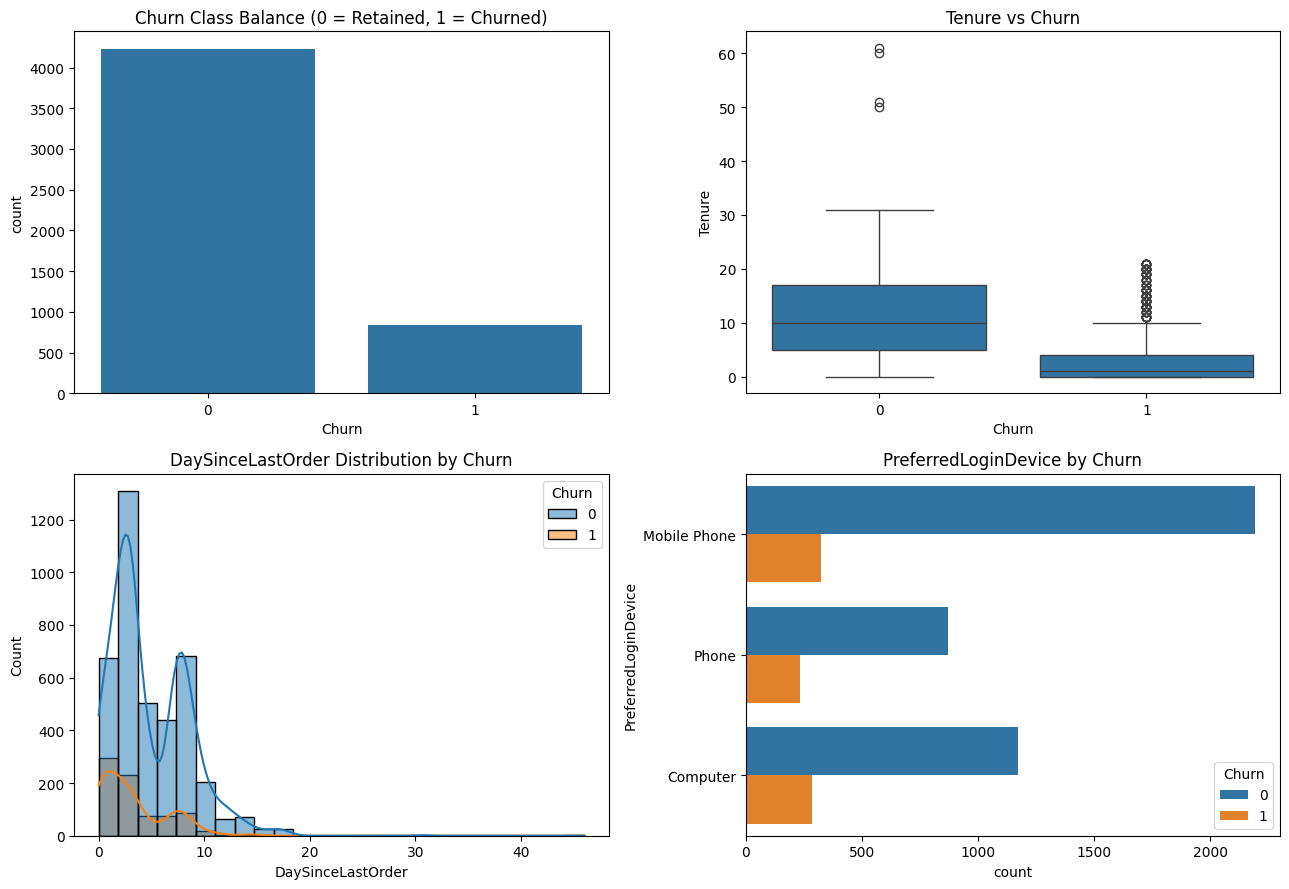

Train shape: (4059, 18) | Test shape: (1015, 18)
Analytical Q1 (random_state=42): Ensures reproducible train/test splits so experiments are consistent and comparable across runs.

PART 2: PREPROCESSING PIPELINES & INSPECTIONS
Learned medians (.statistics_): [  9.     1.    13.     3.     4.     3.     3.     0.    15.     1.
   2.     3.   163.49]
Has .median_ attribute?: False
OneHotEncoder output type: <class 'scipy.sparse._csr.csr_matrix'> | shape: (4059, 21)
Master Pipeline baseline accuracy: 0.8818

PART 3: BIAS-VARIANCE TRADEOFF & REGULARIZATION
Underfitting / High Bias (max_depth=1) -> Train Acc: 0.8436 | Test Acc: 0.8246
Higher Complexity (max_depth=14) -> Train Acc: 0.9953 | Test Acc: 0.9537
L2 (Ridge) -> Acc: 0.8818 | F1: 0.5455 | Zero Coefs: 0.0%
L1 (Lasso) -> Acc: 0.8837 | F1: 0.5786 | Zero Coefs: 14.7%
ElasticNet (l1_ratio=0.5) -> Acc: 0.8818 | F1: 0.5556 | Zero Coefs: 11.8%

PART 4: ENSEMBLE LEARNING
Bagging OOB Score: 0.9576 | Bagging Test Acc: 0.9665
Pasting (bootstrap=

In [1]:
# ==============================================================================
# AIE322 - E-Commerce Customer Churn Classification (Colab Ready Code)
# ==============================================================================
import os
import warnings
warnings.filterwarnings("ignore")

try:
    import kagglehub
except ImportError:
    !pip install -q kagglehub
    import kagglehub

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    BaggingClassifier,
    AdaBoostClassifier,
    VotingClassifier,
    RandomForestClassifier,
)
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# ------------------------------------------------------------------------------
# PART 1: Data Cleaning, EDA & Reproducible Splitting
# ------------------------------------------------------------------------------
print("=" * 70)
print("PART 1: LOADING, CLEANING, EDA & TRAIN/TEST SPLIT")
print("=" * 70)

dataset_path = kagglehub.dataset_download(
    "ankitverma2010/ecommerce-customer-churn-analysis-and-prediction"
)
xlsx_file = os.path.join(dataset_path, "E Commerce Dataset.xlsx")
if os.path.exists(xlsx_file):
    df = pd.read_excel(xlsx_file, sheet_name="E Comm")
else:
    csv_files = [f for f in os.listdir(dataset_path) if f.endswith(".csv")]
    df = pd.read_csv(os.path.join(dataset_path, csv_files[0]))

print(f"Initial shape: {df.shape}")

if "CustomerID" in df.columns:
    df = df.drop(columns=["CustomerID"])

dup_rows = df.duplicated().sum()
print(f"Duplicate rows found: {dup_rows}")
if dup_rows > 0:
    df = df.drop_duplicates().copy()

num_cols_all = [c for c in df.select_dtypes(include=[np.number]).columns if c != "Churn"]
q1 = df[num_cols_all].quantile(0.25)
q3 = df[num_cols_all].quantile(0.75)
iqr = q3 - q1
outliers = ((df[num_cols_all] < (q1 - 1.5 * iqr)) | (df[num_cols_all] > (q3 + 1.5 * iqr))).sum()
print("Outliers per numerical column (1.5 * IQR):")
print(outliers[outliers > 0])

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.countplot(data=df, x="Churn", ax=axes[0, 0])
axes[0, 0].set_title("Churn Class Balance (0 = Retained, 1 = Churned)")

num_plot_cols = [c for c in ["Tenure", "WarehouseToHome", "CashbackAmount", "DaySinceLastOrder"] if c in df.columns]
if num_plot_cols:
    sns.boxplot(data=df, x="Churn", y=num_plot_cols[0], ax=axes[0, 1])
    axes[0, 1].set_title(f"{num_plot_cols[0]} vs Churn")

if len(num_plot_cols) > 1:
    sns.histplot(data=df, x=num_plot_cols[-1], hue="Churn", bins=25, kde=True, ax=axes[1, 0])
    axes[1, 0].set_title(f"{num_plot_cols[-1]} Distribution by Churn")

cat_plot_cols = [c for c in ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"] if c in df.columns]
if cat_plot_cols:
    sns.countplot(data=df, y=cat_plot_cols[0], hue="Churn", ax=axes[1, 1])
    axes[1, 1].set_title(f"{cat_plot_cols[0]} by Churn")

plt.tight_layout()
plt.show()

X = df.drop(columns=["Churn"])
y = df["Churn"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}")
print(
    "Analytical Q1 (random_state=42): Ensures reproducible train/test splits "
    "so experiments are consistent and comparable across runs."
)

# ------------------------------------------------------------------------------
# PART 2: Preprocessing Pipelines (ColumnTransformer & Pipeline)
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("PART 2: PREPROCESSING PIPELINES & INSPECTIONS")
print("=" * 70)

num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

med_imp = SimpleImputer(strategy="median").fit(X_train[num_cols])
print("Learned medians (.statistics_):", np.round(med_imp.statistics_, 3))
print("Has .median_ attribute?:", hasattr(med_imp, "median_"))

freq_imp = SimpleImputer(strategy="most_frequent")
X_train_cat_clean = freq_imp.fit_transform(X_train[cat_cols])
ohe_inspector = OneHotEncoder(handle_unknown="ignore")
ohe_output = ohe_inspector.fit_transform(X_train_cat_clean)
print("OneHotEncoder output type:", type(ohe_output), "| shape:", ohe_output.shape)

num_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler(feature_range=(0, 1))),
])

cat_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", num_transformer, num_cols),
    ("cat", cat_transformer, cat_cols),
])

master_pipe = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=2000, random_state=42)),
])
master_pipe.fit(X_train, y_train)
print(f"Master Pipeline baseline accuracy: {accuracy_score(y_test, master_pipe.predict(X_test)):.4f}")

# ------------------------------------------------------------------------------
# PART 3: Model Complexity, Bias-Variance & Regularization
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("PART 3: BIAS-VARIANCE TRADEOFF & REGULARIZATION")
print("=" * 70)

high_bias_pipe = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", DecisionTreeClassifier(max_depth=1, random_state=42)),
])
deeper_pipe = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", DecisionTreeClassifier(max_depth=14, random_state=42)),
])

for label, pipe in [
    ("Underfitting / High Bias (max_depth=1)", high_bias_pipe),
    ("Higher Complexity (max_depth=14)", deeper_pipe),
]:
    pipe.fit(X_train, y_train)
    tr_s = accuracy_score(y_train, pipe.predict(X_train))
    te_s = accuracy_score(y_test, pipe.predict(X_test))
    print(f"{label} -> Train Acc: {tr_s:.4f} | Test Acc: {te_s:.4f}")

reg_models = [
    ("L2 (Ridge)", LogisticRegression(penalty="l2", solver="saga", max_iter=2000, random_state=42)),
    ("L1 (Lasso)", LogisticRegression(penalty="l1", solver="saga", max_iter=2000, random_state=42)),
    ("ElasticNet (l1_ratio=0.5)", LogisticRegression(penalty="elasticnet", l1_ratio=0.5, solver="saga", max_iter=2000, random_state=42)),
]

for name, est in reg_models:
    p = Pipeline(steps=[("prep", preprocessor), ("clf", est)])
    p.fit(X_train, y_train)
    pred = p.predict(X_test)
    zero_pct = np.mean(p.named_steps["clf"].coef_ == 0) * 100
    print(
        f"{name} -> Acc: {accuracy_score(y_test, pred):.4f} | "
        f"F1: {f1_score(y_test, pred, zero_division=0):.4f} | "
        f"Zero Coefs: {zero_pct:.1f}%"
    )

# ------------------------------------------------------------------------------
# PART 4: Ensemble Learning (Bagging, Pasting, AdaBoost & Voting)
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("PART 4: ENSEMBLE LEARNING")
print("=" * 70)

bagging_pipe = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100, bootstrap=True, oob_score=True, n_jobs=-1, random_state=42
    )),
])
pasting_pipe = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100, bootstrap=False, n_jobs=-1, random_state=42
    )),
])

bagging_pipe.fit(X_train, y_train)
pasting_pipe.fit(X_train, y_train)

oob_score_val = bagging_pipe.named_steps["clf"].oob_score_
bag_test_val = accuracy_score(y_test, bagging_pipe.predict(X_test))
paste_test_val = accuracy_score(y_test, pasting_pipe.predict(X_test))

print(f"Bagging OOB Score: {oob_score_val:.4f} | Bagging Test Acc: {bag_test_val:.4f}")
print(f"Pasting (bootstrap=False) Test Acc: {paste_test_val:.4f}")

ada_pipe = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", AdaBoostClassifier(n_estimators=100, random_state=42)),
])
ada_pipe.fit(X_train, y_train)
ada_pred = ada_pipe.predict(X_test)

print(
    f"AdaBoost -> Acc: {accuracy_score(y_test, ada_pred):.4f} | "
    f"Precision: {precision_score(y_test, ada_pred, zero_division=0):.4f} | "
    f"Recall: {recall_score(y_test, ada_pred, zero_division=0):.4f} | "
    f"F1: {f1_score(y_test, ada_pred, zero_division=0):.4f}"
)

voters = [
    ("lr", LogisticRegression(max_iter=2000, random_state=42)),
    ("rf", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)),
    ("svc", SVC(probability=True, random_state=42)),
]

for v_type in ["hard", "soft"]:
    v_pipe = Pipeline(steps=[
        ("prep", preprocessor),
        ("clf", VotingClassifier(estimators=voters, voting=v_type)),
    ])
    v_pipe.fit(X_train, y_train)
    v_pred = v_pipe.predict(X_test)
    print(f"Voting ({v_type}) -> Acc: {accuracy_score(y_test, v_pred):.4f} | F1: {f1_score(y_test, v_pred, zero_division=0):.4f}")
